In [63]:
%load_ext autoreload
%autoreload 2
import pandas as pd
import numpy as np
import importlib.util
import joblib
import time
import sys
from pathlib import Path

# Fügt den Ordner '../04_VAE' temporär zum Python-Suchpfad hinzu
sys.path.append(str(Path("../04_VAE").resolve()))

# Jetzt funktioniert der spezifische Direkt-Import:
from portfolio_eval import PriceData
from data_prep import DataPrep
from vae_training import Modeltraining

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [110]:
load_commodity = pd.read_csv("../02_Silver/commodity.csv")
load_interest = pd.read_csv("../02_Silver/interest.csv")
makro_ = pd.read_csv("../02_Silver/gmd.csv")
load_makro = pd.read_excel('makro2016.xlsx')

## Funktionen

In [106]:
def top_n_economies(makro_df, n=25):
    gdp = makro_df.query("item_description == 'nGDP_USD' and date.between(2021, 2025)")
    top25_iso3 = gdp.groupby("iso3")["value"].mean().nlargest(n).index.tolist()
    top25 = makro_df[makro_df["iso3"].isin(top25_iso3)].copy()
    return top25, top25_iso3

In [107]:
def add_features(
    df: pd.DataFrame,
    group_cols: list[str],
    date_col: str = "date",
    value_col: str = "value",
    change: str = "pct",  # "pct" | "log" | "diff"
    makro: bool = False
) -> pd.DataFrame:
    """
    Hängt Veränderungen, Volatilitäten und rollierenden 24M-Z-Score pro Gruppe an.

    change:
      "pct"  -> einfache Rendite (P_t / P_{t-n} - 1)
      "log"  -> Log-Rendite ln(P_t / P_{t-n}), nur für Werte > 0
      "diff" -> absolute Differenz P_t - P_{t-n} (bei Zinsen: Prozentpunkte)
    """
    if change not in ("pct", "log", "diff"):
        raise ValueError("change muss 'pct', 'log' oder 'diff' sein")

    out = df.sort_values(group_cols + [date_col]).reset_index(drop=True).copy()
    n_keys = len(group_cols)
    prefix = "ret"

    # Hilfsfunktion: rollierende Statistik pro Gruppe, Index wieder auf Originalindex
    def roll_stat(series: pd.Series, window: int, stat: str) -> pd.Series:
        r = series.groupby([out[c] for c in group_cols]).rolling(window, min_periods=window)
        res = getattr(r, stat)()
        return res.droplevel(list(range(n_keys)))
    # 1.-5. Veränderungen über n Monate
    g = out.groupby(group_cols)[value_col]
    if change == "pct":
        if makro:
            for n in (1, 2, 3, 4, 5):
                out[f"{prefix}_{n}y"] = g.pct_change(periods=n, fill_method=None).replace([np.inf, -np.inf], np.nan)
        else:
            for n in (1, 3, 6, 12, 24):
                out[f"{prefix}_{n}m"] = g.pct_change(periods=n, fill_method=None).replace([np.inf, -np.inf], np.nan)
    elif change == "log":
        logv = np.log(out[value_col].where(out[value_col] > 0))
        gl = logv.groupby([out[c] for c in group_cols])
        if makro:
            for n in (1, 2, 3, 4, 5):
                out[f"{prefix}_{n}y"] = gl.diff(n)
        else:
            for n in (1, 3, 6, 12, 24):
                out[f"{prefix}_{n}m"] = gl.diff(n)
    else:  # diff
        if makro:
            for n in (1, 2, 3, 4, 5):
                out[f"{prefix}_{n}y"] = g.diff(n)
        else:
            for n in (1, 3, 6, 12, 24):
                out[f"{prefix}_{n}m"] = g.diff(n)

    # 6.-10. Volatilität = rollierende Std. der 1M-Veränderungen
    if makro:
        for n in (2, 3, 4, 5):
            out[f"vol_{n}y"] = roll_stat(out[f"{prefix}_1y"], n, "std")
    else:
        for n in (3, 6, 12, 24):
            out[f"vol_{n}m"] = roll_stat(out[f"{prefix}_1m"], n, "std")

    # 11. Rollierender Z-Score (24M inkl. aktuellem Monat)
    if makro:
        mu = roll_stat(out[value_col], 5, "mean")
        sigma = roll_stat(out[value_col], 5, "std")
        out["zscore_5y"] = (out[value_col] - mu) / sigma.replace(0, np.nan)
    else:
        mu = roll_stat(out[value_col], 24, "mean")
        sigma = roll_stat(out[value_col], 24, "std")
        out["zscore_24m"] = (out[value_col] - mu) / sigma.replace(0, np.nan)

    return out

In [108]:
def annual_to_monthly(
    df: pd.DataFrame,
    year_col: str = "date",
    out_col: str = "date",
) -> pd.DataFrame:
    """
    Jede Jahreszeile wird zu 12 Monatszeilen (Januar bis Dezember) mit demselben Wert.
    Alle anderen Spalten (iso3, item_description, change_type, ...) bleiben erhalten.
    """
    out = df.copy()

    # Spalte "date" enthält das Jahr (2019, 2020, ...); falls datetime, Jahr extrahieren
    if pd.api.types.is_datetime64_any_dtype(out[year_col]):
        year = out[year_col].dt.year
    else:
        year = out[year_col].astype(int)

    # Jede Zeile mit den Monaten 1..12 kreuzen
    out = out.drop(columns=[year_col]).assign(_year=year.values)
    out = out.merge(pd.DataFrame({"_month": range(1, 13)}), how="cross")

    out[out_col] = pd.to_datetime(
        {"year": out["_year"], "month": out["_month"], "day": 1}
    )
    out = out.drop(columns=["_year", "_month"])

    # Spalte "date" wieder an die gewohnte Position
    cols = [out_col] + [c for c in out.columns if c != out_col]
    return (
        out[cols]
        .sort_values(["iso3", "item_description", out_col])
        .reset_index(drop=True)
    )

In [4]:
def split_list(lst, n):
    """Teilt eine Liste 'lst' in 'n' möglichst gleich große Teile auf."""
    k, m = divmod(len(lst), n)
    return [
        lst[i * k + min(i, m):(i + 1) * k + min(i + 1, m)]
        for i in range(n)
    ]

In [82]:
def create_monthly_embeddings(
    embeddings: pd.DataFrame,
    end_date: str = "2023-09-30",
    max_ffill_months: int = 15,
) -> pd.DataFrame:
    """
    Wandelt unregelmäßige (jährliche) VAE-Embeddings pro Unternehmen in eine
    monatliche Zeitreihe (Monatsende) per Forward-Fill um.
    Ohne Veröffentlichungsverzug (Point-in-Time Alignment auf Fiscal-Period-End).
    """
    df = embeddings.copy()
    df["Date"] = pd.to_datetime(df["Date"]) + pd.offsets.MonthEnd(0)

    # Falls eine Firma im selben Monat doppelte Einträge hat, den letzten behalten
    df = (
        df.sort_values(["EntityCode", "Date"])
        .drop_duplicates(subset=["EntityCode", "Date"], keep="last")
    )

    global_end = pd.to_datetime(end_date) + pd.offsets.MonthEnd(0)
    emb_cols = [c for c in df.columns if c not in ["EntityCode", "Date"]]

    # Pandas-Version-unabhängiger Monatsende-Anker ('ME' ab 2.2, sonst 'M')
    month_freq = "ME" if pd.__version__ >= "2.2.0" else "M"

    def expand_company(group: pd.DataFrame) -> pd.DataFrame:
        # Startet erst ab dem ersten verfügbaren Bilanzstichtag der Firma (kein bfill in die Vergangenheit!)
        start_m = group["Date"].min()
        end_m = max(group["Date"].max(), global_end)

        monthly_idx = pd.date_range(start=start_m, end=end_m, freq=month_freq)
        out = group.set_index("Date")[emb_cols].reindex(monthly_idx)

        # Fortschreiben bis ein neuer Wert vorliegt (max. 15 Monate Puffer für leicht verspätete Folgebilanz)
        out = out.ffill(limit=max_ffill_months)
        out.index.name = "Date"
        return out.dropna(how="all")

    df_monthly = (
        df.groupby("EntityCode", group_keys=True)
        .apply(expand_company)
        .reset_index()
    )

    # Auf globales Enddatum begrenzen und sauber sortieren
    df_monthly = (
        df_monthly[df_monthly["Date"] <= global_end]
        .sort_values(["Date", "EntityCode"])
        .reset_index(drop=True)
    )

    return df_monthly

## Makro Vorbereitung

In [111]:
#Filterung der Top25 größten Volkswirtschaften nach nGDP
makro25,iso_list = top_n_economies(load_makro, n=25)

In [112]:
#ForwardFill um NaN zu beheben und somit mehrere Features verfügbar zu machen
makro25 = makro25.sort_values(by=['iso3', 'date'])
makro25['value'] = makro25.groupby(['iso3', 'item_description'])['value'].ffill() 

In [113]:
#Rauswurf aller Features die NaN-Werte ab 2021 haben 34 (54 nach FFill) Features übrig von 77
makro2021 = makro25[makro25['date'] >= 2021]
nan_counts = makro2021['value'].isna().groupby(makro2021['item_description']).sum()
zero_nan_features = nan_counts[nan_counts == 0].index.tolist()
#makro_25 = makro25[makro25["item_description"].isin(zero_nan_features)]

In [114]:
#Von Hand ausgewählte Features immer GDP wenn möglich ansonsten USD. Es werden nur die Null NaN Features verwendet bis aus die Zinsdaten cbrate, ltrate und strate
selected_features = ['CA_GDP','CPI', 'REER', 'USDfx','cons_GDP', 'deflator', 'exports_GDP', 'finv_GDP', 'gcons_GDP', 
                     'gen_govdebt_GDP', 'gen_govdef_GDP','gen_govexp_GDP','gen_govrev_GDP','hcons_GDP','imports_GDP',
                     'infl','inv_GDP','nGDP_USD', 'pop','rGDP_USD', 'rGDP_pc_USD','unemp', 'cbrate', 'ltrate', 'strate']
makro25 = makro25[makro25["item_description"].isin(selected_features)]
print(len(selected_features))
na = len(makro25[makro25['value'].isna()])
makro25 = makro25.dropna(subset=['value'])

25


Gewählte Features: ['pop', 'gcons_GDP', 'REER', 'finv_GDP', 'hcons_GDP', 'strate', 'gen_govrev_GDP', 'deflator', 'infl', 'unemp', 'rGDP_USD', 'CA_GDP', 'imports_GDP', 'USDfx', 'gen_govdebt_GDP']

Komplette Korrelationsmatrix (Spearman):
 item_description  CA_GDP   CPI  REER  USDfx  cbrate  cons_GDP  deflator  exports_GDP  finv_GDP  gcons_GDP  gen_govdebt_GDP  gen_govdef_GDP  gen_govexp_GDP  gen_govrev_GDP  hcons_GDP  imports_GDP  infl  inv_GDP  ltrate  nGDP_USD   pop  rGDP_USD  rGDP_pc_USD  strate  unemp
item_description                                                                                                                                                                                                                                                               
CA_GDP              1.00 -0.06  0.01  -0.06   -0.14     -0.47      0.13         0.16     -0.42      -0.12            -0.04            0.06           -0.06           -0.01      -0.45        -0.38 -0.08    -0.50   -0.13 

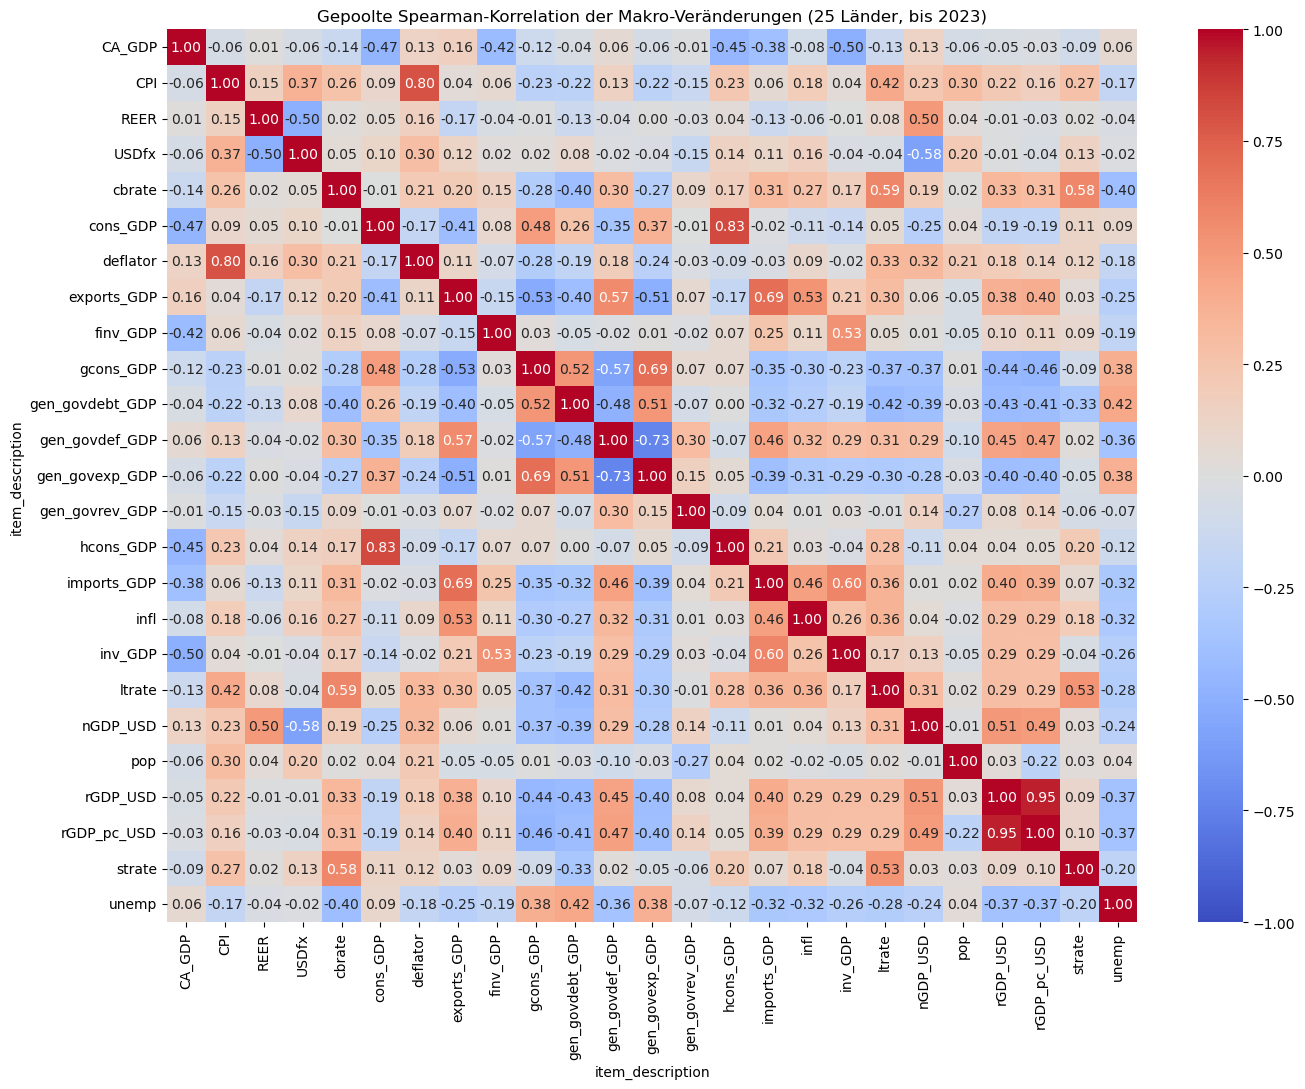

In [117]:
import seaborn as sns
import matplotlib.pyplot as plt

def select_uncorrelated_macro_features(
    df: pd.DataFrame,
    selected_features: list,
    n_features: int = 8,
    max_nan_ratio: float = 0.15,
    train_end_date: str = "2023-12-31",
) -> tuple[list, pd.DataFrame, pd.DataFrame]:
    # 1. Auf die Vorauswahl und den Trainingszeitraum filtern
    sub = df[
        df["item_description"].isin(selected_features)
        & (pd.to_datetime(df["date"]) <= pd.to_datetime(train_end_date))
    ].copy()
    sub = sub.sort_values(["iso3", "item_description", "date"])

    # 2. Features mit zu vielen fehlenden Werten aussortieren
    nan_ratio = sub.groupby("item_description")["value"].apply(lambda s: s.isna().mean())
    valid_items = nan_ratio[nan_ratio <= max_nan_ratio].index.tolist()
    sub = sub[sub["item_description"].isin(valid_items)].copy()

    # 3. Stationäre Veränderungen berechnen (pct_change bei 'pct', diff bei 'diff')
    sub["value"] = sub.groupby(["iso3", "item_description"])["value"].ffill()
    sub["delta"] = np.nan

    is_pct = sub["change_type"] == "pct"
    sub.loc[is_pct, "delta"] = (
        sub[is_pct].groupby(["iso3", "item_description"])["value"].pct_change(fill_method=None)
    )
    sub.loc[~is_pct, "delta"] = (
        sub[~is_pct].groupby(["iso3", "item_description"])["value"].diff()
    )
    sub["delta"] = sub["delta"].replace([np.inf, -np.inf], np.nan)

    # 4. Wide-Format: Zeilen = (iso3, date), Spalten = item_description
    wide = sub.pivot_table(index=["iso3", "date"], columns="item_description", values="delta")

    # 5. Komplette gepoolte Spearman-Korrelationsmatrix (mit Vorzeichen und als Betrag)
    full_corr_signed = wide.corr(method="spearman")
    corr_abs = full_corr_signed.abs()

    # 6. Greedy Minimax-Selektion
    first_feat = corr_abs.mean().idxmin()
    chosen = [first_feat]

    while len(chosen) < n_features and len(chosen) < len(corr_abs.columns):
        remaining = [c for c in corr_abs.columns if c not in chosen]
        max_corr_to_chosen = corr_abs.loc[remaining, chosen].max(axis=1)
        next_feat = max_corr_to_chosen.idxmin()
        chosen.append(next_feat)

    return chosen, full_corr_signed.loc[chosen, chosen], full_corr_signed

# Aufruf:
top_macro_features, corr_selected, corr_full = select_uncorrelated_macro_features(
    makro25,
    selected_features=selected_features,
    n_features=15,
    train_end_date="2023-12-31",
)

print("Gewählte Features:", top_macro_features)

# 1. Komplette Korrelationsmatrix aller validen Kandidaten als Tabelle ausgeben:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
print("\nKomplette Korrelationsmatrix (Spearman):\n", corr_full.round(2))

# 2. Optional: Komplette Matrix als Heatmap plotten (sehr übersichtlich bei 20+ Features)
plt.figure(figsize=(14, 11))
sns.heatmap(corr_full, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Gepoolte Spearman-Korrelation der Makro-Veränderungen (25 Länder, bis 2023)")
plt.tight_layout()
plt.show()

In [124]:
#Features berechnen mit log für pct (es sind alle Werte > 0) weil somit extreme ausreißer keine Extremwerte rausbringen die die Skalierung kaputt machen
makro_pct = makro25[makro25['change_type'] == 'pct']
makro_diff = makro25[makro25['change_type'] == 'diff']
makro_pct_feat = add_features(makro_pct[['date', 'countryname', 'iso3','item_description', 'value']], group_cols=["iso3", "item_description"], change="log", makro=True)
makro_diff_feat = add_features(makro_diff[['date', 'countryname', 'iso3','item_description', 'value']], group_cols=["iso3", "item_description"], change="diff", makro=True)
makro = pd.concat([makro_diff_feat, makro_pct_feat])
makro

,date,countryname,iso3,item_description,value,ret_1y,ret_2y,ret_3y,ret_4y,ret_5y,vol_2y,vol_3y,vol_4y,vol_5y,zscore_5y
0,2016,Argentina,ARG,CA_GDP,-2.732825,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2017,Argentina,ARG,CA_GDP,-4.848343,-2.115518,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2018,Argentina,ARG,CA_GDP,-4.686622,0.161721,-1.953797,NaN,NaN,NaN,1.610251,NaN,NaN,NaN,NaN
3,2019,Argentina,ARG,CA_GDP,-0.527503,4.159119,4.320840,2.205322,NaN,NaN,2.826587,3.176373,NaN,NaN,NaN
4,2020,Argentina,ARG,CA_GDP,0.595520,1.123023,5.282142,5.443863,3.328345,NaN,2.146844,2.086511,2.600740,NaN,1.244287
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2195,2022,United States,USA,rGDP_pc_USD,64284.910000,0.021206,0.078287,0.052533,0.072829,0.096163,0.025367,0.041541,0.033947,0.029488,1.346162
2196,2023,United States,USA,rGDP_pc_USD,65817.580000,0.023562,0.044768,0.101849,0.076095,0.096391,0.001666,0.020067,0.034053,0.029496,1.229441
2197,2024,United States,USA,rGDP_pc_USD,66880.820000,0.016025,0.039587,0.060794,0.117874,0.092120,0.005329,0.003856,0.018675,0.029521,1.039597
2198,2025,United States,USA,rGDP_pc_USD,67891.230000,0.014995,0.031020,0.054582,0.075788,0.132869,0.000729,0.004677,0.004105,0.017421,1.173517


In [ ]:
#Monatliche chunks erstellen
makro = makro[makro['date'] >= 2021]
makro = annual_to_monthly(makro)
makro = makro.drop(columns=['value'])
makro

,date,countryname,iso3,item_description,ret_1y,ret_2y,ret_3y,ret_4y,ret_5y,vol_2y,vol_3y,vol_4y,vol_5y,zscore_5y
0,2021-01-01,Argentina,ARG,CA_GDP,0.645502,1.768525,5.927644,6.089365,3.973847,0.337658,1.905755,1.801128,2.253852,0.988353
1,2021-02-01,Argentina,ARG,CA_GDP,0.645502,1.768525,5.927644,6.089365,3.973847,0.337658,1.905755,1.801128,2.253852,0.988353
2,2021-03-01,Argentina,ARG,CA_GDP,0.645502,1.768525,5.927644,6.089365,3.973847,0.337658,1.905755,1.801128,2.253852,0.988353
3,2021-04-01,Argentina,ARG,CA_GDP,0.645502,1.768525,5.927644,6.089365,3.973847,0.337658,1.905755,1.801128,2.253852,0.988353
4,2021-05-01,Argentina,ARG,CA_GDP,0.645502,1.768525,5.927644,6.089365,3.973847,0.337658,1.905755,1.801128,2.253852,0.988353
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44419,2026-08-01,United States,USA,unemp,-0.037269,0.080545,0.464704,0.468646,-1.248354,0.109660,0.213148,0.189698,0.836552,0.777122
44420,2026-09-01,United States,USA,unemp,-0.037269,0.080545,0.464704,0.468646,-1.248354,0.109660,0.213148,0.189698,0.836552,0.777122
44421,2026-10-01,United States,USA,unemp,-0.037269,0.080545,0.464704,0.468646,-1.248354,0.109660,0.213148,0.189698,0.836552,0.777122
44422,2026-11-01,United States,USA,unemp,-0.037269,0.080545,0.464704,0.468646,-1.248354,0.109660,0.213148,0.189698,0.836552,0.777122


In [147]:
#Aufteilung in Makro, Zins und Currency
zins_features = ['ltrate', 'strate', 'cbrate']
currency_features = ['USDfx']
makro_features = makro[~makro['item_description'].isin(zins_features+currency_features)]['item_description'].unique().tolist()
makro = makro[makro['date'] >=  '2021-06-01']
makro_data = makro[makro['item_description'].isin(makro_features)]
zins_data = makro[makro['item_description'].isin(zins_features)]
currency_data = makro[makro['item_description'].isin(currency_features)]
currency_data = currency_data[currency_data['iso3'] != 'USA']
zins_data

,date,countryname,iso3,item_description,ret_1y,ret_2y,ret_3y,ret_4y,ret_5y,vol_2y,vol_3y,vol_4y,vol_5y,zscore_5y
293,2021-06-01,Argentina,ARG,cbrate,0.000,-17.000000,-21.2520,9.2500,13.249700,12.020815,8.846760,20.133396,17.452351,-0.452251
294,2021-07-01,Argentina,ARG,cbrate,0.000,-17.000000,-21.2520,9.2500,13.249700,12.020815,8.846760,20.133396,17.452351,-0.452251
295,2021-08-01,Argentina,ARG,cbrate,0.000,-17.000000,-21.2520,9.2500,13.249700,12.020815,8.846760,20.133396,17.452351,-0.452251
296,2021-09-01,Argentina,ARG,cbrate,0.000,-17.000000,-21.2520,9.2500,13.249700,12.020815,8.846760,20.133396,17.452351,-0.452251
297,2021-10-01,Argentina,ARG,cbrate,0.000,-17.000000,-21.2520,9.2500,13.249700,12.020815,8.846760,20.133396,17.452351,-0.452251
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44347,2026-08-01,United States,USA,strate,-0.625,-1.694167,-1.7975,1.1525,3.336111,0.314073,0.483435,1.817953,1.788096,-0.481532
44348,2026-09-01,United States,USA,strate,-0.625,-1.694167,-1.7975,1.1525,3.336111,0.314073,0.483435,1.817953,1.788096,-0.481532
44349,2026-10-01,United States,USA,strate,-0.625,-1.694167,-1.7975,1.1525,3.336111,0.314073,0.483435,1.817953,1.788096,-0.481532
44350,2026-11-01,United States,USA,strate,-0.625,-1.694167,-1.7975,1.1525,3.336111,0.314073,0.483435,1.817953,1.788096,-0.481532


## Rohstoffe Vorbereitung

In [122]:
commodity = load_commodity[['date', 'commodity_name', 'value']]
commodity = add_features(commodity, group_cols=["commodity_name"], change="log", makro=False)
commodity = commodity[commodity['date'] >= '2021-01-01']
commodity = commodity.drop(columns=['value'])
commodity

,date,commodity_name,ret_1m,ret_3m,ret_6m,ret_12m,ret_24m,vol_3m,vol_6m,vol_12m,vol_24m,zscore_24m
24,2021-01-01,APSP crude oil($/bbl),0.091429,0.263258,0.209688,-0.177684,-0.086166,0.034842,0.068226,0.222369,0.159776,0.033351
25,2021-02-01,APSP crude oil($/bbl),0.124563,0.336603,0.311059,0.081048,-0.040109,0.018097,0.076752,0.222287,0.161076,0.590018
26,2021-03-01,APSP crude oil($/bbl),0.058918,0.274910,0.436542,0.646730,-0.024857,0.032823,0.050714,0.152519,0.161292,0.883972
27,2021-04-01,APSP crude oil($/bbl),-0.012701,0.170780,0.434038,0.951675,-0.111841,0.068654,0.051536,0.102036,0.160502,0.870463
28,2021-05-01,APSP crude oil($/bbl),0.042541,0.088758,0.425362,0.701403,-0.041133,0.037526,0.052363,0.076912,0.160700,1.113450
...,...,...,...,...,...,...,...,...,...,...,...,...
10039,2026-05-01,Zinc,0.036018,0.045273,0.090467,0.274584,0.162793,0.051418,0.034951,0.031008,0.044730,2.080709
10040,2026-06-01,Zinc,0.017416,0.106180,0.112511,0.287459,0.230877,0.017673,0.033597,0.030535,0.043056,2.012599
10041,2026-07-01,Zinc,0.015432,0.068866,0.113950,0.263044,0.257735,0.011356,0.033562,0.030191,0.042834,1.935216
10042,2026-08-01,Zinc,0.077798,0.110646,0.155919,0.330823,0.355973,0.035448,0.041263,0.033877,0.044390,2.434277


## Returns Vorbereitung

In [2]:
data = joblib.load("../../data/03_gold/full_data.pkl")
print(len(data['entity_codes'].unique()))

7987


In [98]:
#Alle verfügbaren EntityCodes in viele verschiedene Listen splitten, damit es beim download in keine Rate Limit Probleme läuft
codes = list(entities.unique())
code_lists = split_list(codes, 300)

In [99]:
weekly_returns = []
monthly_returns = []

for codes in code_lists:
    weekly, monthly = PriceData.execute(codes, '2019-05-01', '2026-09-30', 0.00)
    weekly_returns.append(weekly[0])
    monthly_returns.append(monthly[1])
    time.sleep(3)

$0007.HK: possibly delisted; no price data found  (1d 2019-05-01 -> 2026-09-30)

1 Failed download:
['0007.HK']: possibly delisted; no price data found  (1d 2019-05-01 -> 2026-09-30)


Eingangs-Ticker:          26
Nutzbare Ticker nach 0.0 Filterung: 23
Eingangs-Ticker:          26
Nutzbare Ticker nach 0.0 Filterung: 23
Eingangs-Ticker:          26
Nutzbare Ticker nach 0.0 Filterung: 26
Eingangs-Ticker:          26
Nutzbare Ticker nach 0.0 Filterung: 26
Eingangs-Ticker:          26
Nutzbare Ticker nach 0.0 Filterung: 26
Eingangs-Ticker:          26
Nutzbare Ticker nach 0.0 Filterung: 26
Eingangs-Ticker:          26
Nutzbare Ticker nach 0.0 Filterung: 25
Eingangs-Ticker:          26
Nutzbare Ticker nach 0.0 Filterung: 25
Eingangs-Ticker:          26
Nutzbare Ticker nach 0.0 Filterung: 25
Eingangs-Ticker:          26
Nutzbare Ticker nach 0.0 Filterung: 25
Eingangs-Ticker:          26
Nutzbare Ticker nach 0.0 Filterung: 25
Eingangs-Ticker:          26
Nutzbare Ticker nach 0.0 Filterung: 25


$0195.HK: possibly delisted; no price data found  (1d 2019-05-01 -> 2026-09-30) (Yahoo error = "No data found, symbol may be delisted")

1 Failed download:
['0195.HK']: possibly delisted; no price data found  (1d 2019-05-01 -> 2026-09-30) (Yahoo error = "No data found, symbol may be delisted")


Eingangs-Ticker:          26
Nutzbare Ticker nach 0.0 Filterung: 25
Eingangs-Ticker:          26
Nutzbare Ticker nach 0.0 Filterung: 25


$0232.HK: possibly delisted; no price data found  (1d 2019-05-01 -> 2026-09-30)

1 Failed download:
['0232.HK']: possibly delisted; no price data found  (1d 2019-05-01 -> 2026-09-30)


Eingangs-Ticker:          26
Nutzbare Ticker nach 0.0 Filterung: 25
Eingangs-Ticker:          26
Nutzbare Ticker nach 0.0 Filterung: 25


... (254 outputs left out)

$XOMA: possibly delisted; no price data found  (1d 2019-05-01 -> 2026-09-30) (Yahoo error = "No data found, symbol may be delisted")

1 Failed download:
['XOMA']: possibly delisted; no price data found  (1d 2019-05-01 -> 2026-09-30) (Yahoo error = "No data found, symbol may be delisted")


Eingangs-Ticker:          25
Nutzbare Ticker nach 0.0 Filterung: 13
Eingangs-Ticker:          25
Nutzbare Ticker nach 0.0 Filterung: 13
Eingangs-Ticker:          25
Nutzbare Ticker nach 0.0 Filterung: 16
Eingangs-Ticker:          25
Nutzbare Ticker nach 0.0 Filterung: 16


$ZTEK: possibly delisted; no price data found  (1d 2019-05-01 -> 2026-09-30) (Yahoo error = "No data found, symbol may be delisted")

1 Failed download:
['ZTEK']: possibly delisted; no price data found  (1d 2019-05-01 -> 2026-09-30) (Yahoo error = "No data found, symbol may be delisted")


Eingangs-Ticker:          25
Nutzbare Ticker nach 0.0 Filterung: 16
Eingangs-Ticker:          25
Nutzbare Ticker nach 0.0 Filterung: 16


In [147]:
price_data = pd.concat(weekly_returns, axis=1).reset_index()
price_data
price_data = price_data.sort_values(by=['Date'])
nan_counts = price_data.isna().sum()
#Hier werden die Unternehmen rausgefiltert, die die ersten Monate/Tage NaNs haben weil die nicht detected werden sind nur ca 5 Stück
bad_tickers = nan_counts[nan_counts > 0].index.tolist()
eval_return_data = price_data.drop(columns=bad_tickers)
eval_return_data

Ticker,Date,0001.HK,0002.HK,0003.HK,0004.HK,0005.HK,0006.HK,0008.HK,0010.HK,0012.HK,...,ZG,ZION,ZS,ZTS,ZUC.MI,ZUMZ,ZV.MI,ZVRA,ZWS,ZYME
0,2019-01-11,0.034551,0.023622,0.023342,0.092909,0.016317,-0.003646,0.039911,0.062753,0.043050,...,0.106783,0.032144,0.082116,0.015337,0.020100,0.117380,0.027555,0.211982,0.067885,0.063673
1,2019-01-18,0.017341,-0.004945,0.002401,0.002237,-0.000764,-0.006405,0.012793,0.000000,0.017689,...,-0.009384,0.069561,0.003319,-0.015140,-0.034483,0.070784,0.008938,0.003802,0.028932,0.001890
2,2019-01-25,0.022728,0.005522,0.025150,0.029018,0.008416,-0.011970,-0.004210,0.033333,0.028968,...,-0.041149,0.034644,0.011907,0.001182,0.015306,0.005053,0.007752,0.045455,-0.019406,-0.003774
3,2019-02-01,-0.022223,-0.006590,-0.001168,0.021692,0.003035,-0.021435,-0.004229,0.071429,0.001126,...,0.049089,-0.008011,0.052953,0.028929,0.000000,0.053205,0.005494,0.009058,0.064621,-0.001263
4,2019-02-08,-0.003788,0.016031,0.014035,0.002123,-0.003782,-0.000952,0.008493,-0.019355,0.006749,...,0.037669,0.015531,0.002897,-0.003558,0.005025,-0.070803,0.010929,-0.120287,-0.015175,-0.016435
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
398,2026-08-28,-0.009181,-0.013785,-0.017333,-0.060548,-0.009208,-0.039231,-0.011070,-0.012500,-0.040397,...,-0.004622,-0.005283,0.013673,-0.005017,-0.050847,-0.004926,0.017417,-0.025695,-0.019588,-0.013952
399,2026-09-04,-0.004277,-0.010416,-0.020690,-0.021984,0.032838,0.005000,-0.004664,-0.004747,-0.060213,...,-0.035236,0.023458,-0.078326,-0.019783,-0.017857,-0.008251,-0.007133,0.072201,-0.009157,0.032543
400,2026-09-11,-0.014316,0.016181,0.011268,-0.028751,-0.020396,0.028148,0.014995,-0.031796,-0.023952,...,-0.059173,-0.008938,-0.030978,-0.037462,0.018182,-0.193012,-0.037356,-0.031452,-0.030036,-0.101062
401,2026-09-18,-0.003003,-0.013376,-0.012535,0.037675,-0.010410,-0.022059,-0.021237,0.000821,-0.004601,...,-0.089678,-0.051200,0.199161,-0.021516,-0.062500,-0.092784,-0.005970,-0.033306,-0.002382,0.012576


In [100]:
mon_price = pd.concat(monthly_returns, axis=1).reset_index()
df_long = mon_price.melt(
    id_vars=['Date'],        # Die Spalte, die fest als Referenz bestehen bleibt
    var_name='EntityCode',       # Name für die neue Spalte mit den Ticker-Namen
    value_name='value'       # Name für die Spalte mit den Renditewerten
)
df_long = df_long.rename(columns={'Date': 'date'})
df_long = df_long.sort_values(by=['EntityCode', 'date']).reset_index(drop=True)
monthly_history_features = add_features(df_long, group_cols=["EntityCode"], change="log")
monthly_history_features = monthly_history_features[monthly_history_features['date'] >= '01-01-2021']
monthly_history_features['EntityCode'].nunique()

5514

## VAE Embeddings

In [ ]:
vae_data = DataPrep.full_data_prep(0.7, 0.15, 0.15, '2023-12-31', 1)
vae_train = vae_data['train']
vae_train_mask = vae_data['train_mask']
vae_val = vae_data['val']
vae_val_mask = vae_data['val_mask']
usable_features = vae_data['usable_features']
scaler = vae_data['scaler']

In [59]:
lr = 0.001666473454836989
dropout_rate = 0.1
batch_size = 256
latent_dim = 64
emb_dim = 8
hidden_dims = (2048, 1024, 512, 256, 128, 64)
activation = 'leaky_relu'
beta = 0.05597595564421984
free_bits = 0.7000000000000001
kl_warmup_epochs = 60
epochs = int(np.mean([198, 148, 197]))
device = "cuda"
print_every = 10
eval_every = 10
model, finale_metrics, history = Modeltraining.train_vae(
    vae_train, vae_train_mask, vae_val, vae_val_mask, 
    emb_dim=emb_dim, hidden_dims=hidden_dims, latent_dim=latent_dim, dropout_rate=dropout_rate,
    batch_size=batch_size, lr=lr, epochs=epochs, beta=beta, activation_fun=activation, device=device, 
    print_every=print_every, eval_every=eval_every, feature_names=usable_features, 
    kl_warmup_epochs=kl_warmup_epochs, free_bits=free_bits, scaler=scaler, early_stopping_patience=169
)

# 2. Latent Embeddings für Testmenge extrahieren
latent_mu = Modeltraining.get_latent_embeddings(model,vae_train, vae_train_mask, device=device)

Epoch   1 | train: loss=1.4488 recon=1.3961 kl=56.4553 | val: loss=1.4178 recon=1.3520 kl=70.5046 val_rel_err=151.19%
Epoch  10 | train: loss=1.1761 recon=0.7446 kl=46.2435 | val: loss=1.1882 recon=0.7596 kl=45.9466 val_rel_err=140.22%
Epoch  20 | train: loss=1.5242 recon=0.6765 kl=45.4314 | val: loss=1.5200 recon=0.6777 kl=45.1439 val_rel_err=136.08%
Epoch  30 | train: loss=1.8923 recon=0.6293 kl=45.1273 | val: loss=1.8947 recon=0.6368 kl=44.9445 val_rel_err=133.93%
Epoch  40 | train: loss=2.2840 recon=0.6044 kl=45.0099 | val: loss=2.2967 recon=0.6227 kl=44.8580 val_rel_err=133.29%
Epoch  50 | train: loss=2.6874 recon=0.5905 kl=44.9526 | val: loss=2.6984 recon=0.6073 kl=44.8275 val_rel_err=134.19%
Epoch  60 | train: loss=3.0862 recon=0.5723 kl=44.9103 | val: loss=3.0948 recon=0.5863 kl=44.8130 val_rel_err=133.50%
Epoch  70 | train: loss=3.0797 recon=0.5655 kl=44.9151 | val: loss=3.0854 recon=0.5768 kl=44.8157 val_rel_err=133.22%
Epoch  80 | train: loss=3.0622 recon=0.5474 kl=44.9271 |

In [88]:
emb = pd.DataFrame(latent_mu)
entities = vae_data['train_entities']
dates = vae_data['train_dates']
embeddings = pd.concat([dates.reset_index(drop=True), entities.reset_index(drop=True), emb.reset_index(drop=True)], axis=1)

In [96]:
df_monthly_emb = create_monthly_embeddings(
    embeddings,
    end_date="2023-09-30",
    max_ffill_months=12,
)
df_monthly_emb = df_monthly_emb.rename(columns={'Date': 'date'})
df_monthly_emb['date'].min()

Timestamp('2021-06-30 00:00:00')

## Zusammenführung VAE Embeddings mit Kursinfo

In [127]:
monthly_history_features
df_monthly_emb
company = pd.merge(df_monthly_emb, monthly_history_features, on=['EntityCode', 'date'], how='inner')
company = company.drop(columns=['value'])
company

,EntityCode,date,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,ret_1m,ret_3m,ret_6m,ret_12m,ret_24m,vol_3m,vol_6m,vol_12m,vol_24m,zscore_24m
0,0016.HK,2021-06-30,-0.029530,-0.182836,0.537187,0.772128,-0.872188,-0.554616,-0.800687,0.718644,-0.803068,-0.656153,-0.437749,0.487317,-0.717227,-0.692517,0.431020,-0.619476,-0.036294,0.433977,-0.478571,0.703258,-0.240881,-0.126122,0.029829,-0.738591,-0.467280,-0.889817,0.618940,0.459144,-0.185559,0.782399,0.497748,-0.785979,0.448710,-0.794074,0.172581,0.653223,0.772773,0.736968,0.243899,-0.593165,0.819608,0.785331,-0.816402,-0.744589,-0.782839,-0.081206,0.016885,0.950907,-0.015208,0.599462,0.180787,0.172623,-0.529367,0.906961,-0.841016,-0.644165,-0.679746,0.707165,-0.860605,-0.575578,0.729800,-0.732602,-0.915591,-0.317592,-0.029802,-0.017988,0.155276,0.203092,-0.046122,0.022985,0.075695,0.067386,0.076757,1.102000
1,0026.HK,2021-06-30,-0.390792,-0.005598,-0.896155,-0.967477,-0.225360,-0.417083,0.019515,-0.935359,0.018937,-0.808717,-0.885729,0.261233,-0.052473,0.467294,0.867004,0.082819,0.552635,-0.948350,0.545465,-0.506579,-0.356171,-0.282926,0.515137,-0.828294,-0.051227,0.622516,-0.557562,0.689730,-0.807073,0.184655,0.848737,-0.311604,0.881102,0.028872,-0.229534,-0.878865,0.083526,-0.474200,-0.247397,0.468853,-0.900370,-0.018728,-0.353650,-0.776965,-0.024907,-0.428119,-0.338982,0.127667,-0.099572,0.399865,-0.453872,0.364869,-0.521448,0.311968,-0.397016,0.192212,0.153818,-0.911733,-0.259188,0.033804,-0.919041,0.862081,0.880209,-0.859130,0.013705,0.107906,0.131686,0.257992,0.325631,0.021542,0.023949,0.026097,0.051327,1.895486
2,0029.HK,2021-06-30,-0.307629,0.073661,-0.776163,-0.819058,-0.254048,-0.352422,0.117727,-0.769365,0.111066,-0.783955,-0.884160,0.171338,0.049927,-0.008146,0.868328,-0.406527,0.503303,-0.890204,0.579610,-0.640751,-0.196664,-0.254355,0.457769,-0.797261,-0.484295,0.600112,-0.130478,0.751839,-0.808612,0.189944,0.839063,-0.301287,0.888328,0.132283,-0.293734,-0.815544,-0.020037,-0.498047,-0.327913,0.481632,-0.917141,-0.128722,-0.358187,-0.647837,0.069129,-0.363926,-0.282127,0.151784,-0.075158,0.433627,-0.306748,0.381380,-0.678607,0.327659,-0.422151,-0.318735,-0.357483,-0.768743,-0.273212,-0.459694,-0.736682,0.777553,0.873539,-0.911280,-0.019803,0.045296,-0.034336,0.175109,0.591226,0.032275,0.032153,0.057599,0.106849,0.853833
3,0092.HK,2021-06-30,-0.601611,0.039418,0.309162,-0.486455,0.471004,0.155235,0.841957,-0.476293,0.852060,0.792578,-0.564633,-0.276525,0.807427,-0.017108,0.561893,-0.140380,0.687137,-0.775165,0.425412,-0.099290,0.301820,-0.579436,0.656937,0.806959,-0.215189,0.968961,-0.010155,-0.716055,0.712620,-0.611266,0.532041,0.372940,0.567497,0.843247,-0.196416,-0.703023,-0.775012,-0.186436,-0.330231,0.494520,-1.127958,-0.838756,0.395226,0.790100,0.843603,-0.607390,-0.607843,-0.538396,0.015932,0.126770,-0.578905,0.650231,0.664918,-0.501762,0.275266,-0.171671,-0.198767,-0.451376,0.486305,-0.188829,-0.418058,0.592908,1.091793,-0.562771,0.000000,-0.330565,0.000000,0.042111,-0.718595,0.165177,0.159895,0.117188,0.144480,-0.621973
4,0131.HK,2021-06-30,-0.600810,-0.055903,-0.779885,-0.477572,-0.773146,-0.840498,0.497189,-0.509362,0.513381,-0.622774,-0.802106,0.706960,0.463119,0.712571,0.784514,0.635169,0.763964,-0.713010,0.425217,-0.859106,0.166718,-0.542344,0.666941,-0.698658,0.623453,-0.176152,-0.732355,0.262038,-0.652019,0.784066,0.839289,-0.853724,0.792593,0.503716,-0.178631,-0.334481,-0.452820,-0.402832,-0.147204,0.269142,-0.460974,-0.501829,-0.852570,-0.897787,0.476665,-0.596411,-0.513086,0.709965,-0.363241,0.606264,-0.703522,0.543835,-0.027233,0.823104,-0.851119,0.670932,0.670136,-0.431546,-0.811825,0.633057,-0.586366,0.509960,0.316575,-0.535976,0.000000,-0.028472,-0.056109,-0.224387,-0.267761,0.032678,0.026254,0.055689,0.105143,-0.805810
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,